# Modèle Naive Bayes

### Définition du Naive Bayes

Le Naive Bayes est une famille de classificateurs probabilistes basés sur l'application du théorème de Bayes avec une forte (naïve) hypothèse d'indépendance entre les caractéristiques. Il est particulièrement utile pour les grandes bases de données en raison de sa simplicité et de son efficacité computationnelle.

#### Principe de Fonctionnement

Le modèle Naive Bayes est basé sur le théorème de Bayes qui permet de calculer la probabilité d'une classe donnée un ensemble de caractéristiques. Le théorème de Bayes est exprimé comme suit :

$P(C_k | \mathbf{x}) = \frac{P(C_k) \cdot P(\mathbf{x} | C_k)}{P(\mathbf{x})}$

Où :
- $P(C_k | \mathbf{x})$ est la probabilité de la classe $C_k$ donnée les caractéristiques $\mathbf{x}$
- $P(C_k)$ est la probabilité a priori de la classe $C_k$
- $ P(\mathbf{x} | C_k) $ est la probabilité de $\mathbf{x}$ donnée la classe $ C_k $
- $ P(\mathbf{x}) $ est la probabilité de l'ensemble des caractéristiques $\mathbf{x} $

#### Hypothèse d'Indépendance

Le Naive Bayes fait l'hypothèse que les caractéristiques sont conditionnellement indépendantes les unes des autres, étant donné la classe :

$ P(\mathbf{x} | C_k) = \prod_{i=1}^{n} P(x_i | C_k) $

Cette hypothèse simplifie considérablement le calcul des probabilités et rend le modèle très efficace même avec un grand nombre de caractéristiques.

#### Types de Modèles Naive Bayes

Il existe plusieurs variantes du Naive Bayes en fonction du type de données :

- **Gaussian Naive Bayes** : Utilisé pour les caractéristiques continues et suppose que les caractéristiques suivent une distribution normale (gaussienne).
- **Multinomial Naive Bayes** : Utilisé pour les données discrètes, comme le comptage de mots dans le traitement du langage naturel.
- **Bernoulli Naive Bayes** : Utilisé pour les données binaires.

#### Fonction de Décision

Pour prédire la classe la plus probable pour un ensemble de caractéristiques, le Naive Bayes choisit la classe $ C_k $ qui maximise $ P(C_k | \mathbf{x}) $. En pratique, cela revient à choisir la classe qui maximise :

$ P(C_k) \cdot \prod_{i=1}^{n} P(x_i | C_k) $

#### Avantages et Inconvénients

##### Avantages :
- Simple à implémenter et très rapide à entraîner.
- Fonctionne bien avec des grands ensembles de données.
- Peu sensible aux données manquantes.
- Performant pour les problèmes de classification de texte et les systèmes de recommandation.

##### Inconvénients :
- L'hypothèse d'indépendance conditionnelle est souvent irréaliste dans les données réelles, ce qui peut affecter la précision du modèle.
- Ne prend pas en compte les interactions entre les caractéristiques.
- Les probabilités prédites peuvent être moins précises comparées à d'autres modèles de classification sophistiqués.

Le Naive Bayes est un algorithme de classification robuste et efficace, particulièrement adapté pour les applications où la rapidité et la simplicité sont essentielles.


## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import pickle

## 2. Chargement des données préparées

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 45)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (70/30)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3087
Taille ensemble de test: 1323


## 4. Entraînement du modèle Naive Bayes

Naive Bayes est une méthode de classification probabiliste fondée sur le théorème de Bayes, qui suppose que les caractéristiques des données sont indépendantes les unes des autres. Le modèle GaussianNB est adapté aux cas où les caractéristiques suivent une distribution normale (gaussienne).

In [4]:
# Initialisation et entraînement du modèle
nb = GaussianNB()
nb.fit(X_train, y_train)

print("Modèle entraîné avec succès!")

Modèle entraîné avec succès!


## 5. Prédictions

In [5]:
# Prédictions sur l'ensemble de test
y_pred = nb.predict(X_test)
y_proba = nb.predict_proba(X_test)[:, 1]

print("Prédictions effectuées!")

Prédictions effectuées!


## 6. Évaluation du modèle

### 6.1 Matrice de confusion

Matrice de Confusion (Naive Bayes) :
 [[973 142]
 [119  89]]


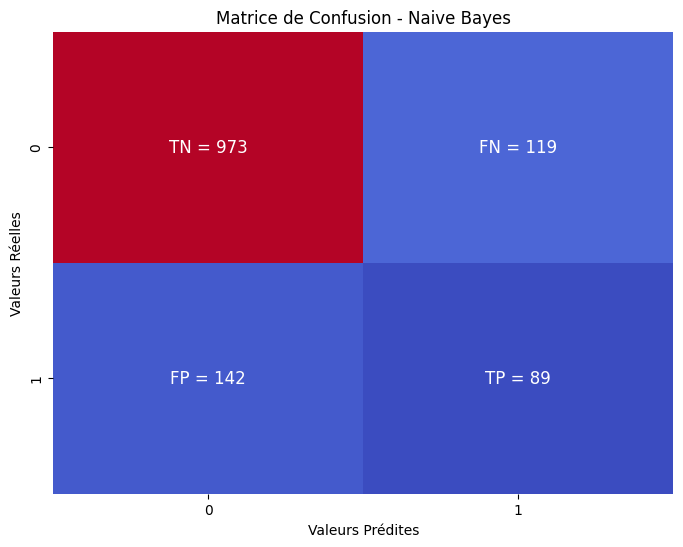

In [6]:
# Matrice de confusion
conf_matrix = confusion_matrix(y_test, y_pred)
print("Matrice de Confusion (Naive Bayes) :\n", conf_matrix)

# Visualisation
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=12)
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=12)
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=12)
plt.title("Matrice de Confusion - Naive Bayes")
plt.ylabel('Valeurs Réelles')
plt.xlabel('Valeurs Prédites')
plt.show()

### 6.2 Rapport de classification

In [7]:
# Rapport de classification
class_report = classification_report(y_test, y_pred)
print("Rapport de Classification (Naive Bayes) :\n", class_report)

Rapport de Classification (Naive Bayes) :
               precision    recall  f1-score   support

           0       0.89      0.87      0.88      1115
           1       0.39      0.43      0.41       208

    accuracy                           0.80      1323
   macro avg       0.64      0.65      0.64      1323
weighted avg       0.81      0.80      0.81      1323



### 6.3 Score AUC-ROC

In [8]:
# AUC-ROC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"AUC-ROC (Naive Bayes) : {roc_auc:.4f}")

AUC-ROC (Naive Bayes) : 0.7398


### 6.4 Courbe ROC

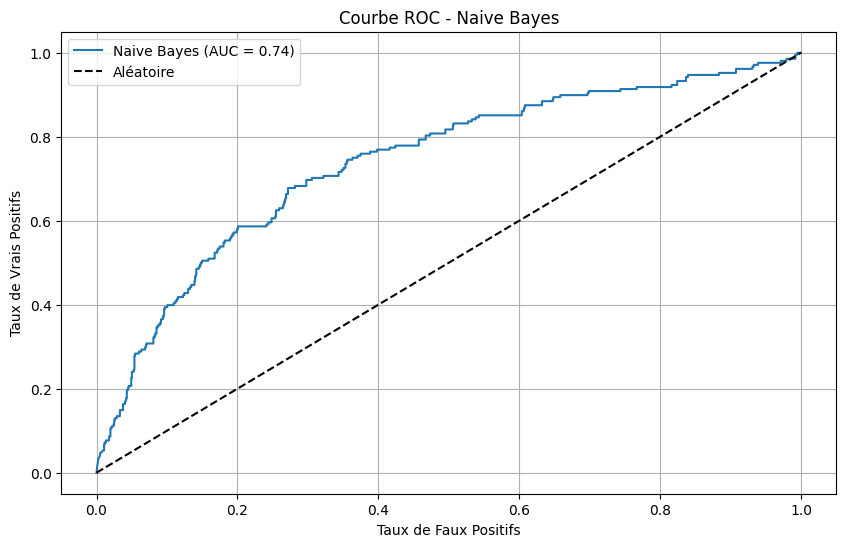

In [9]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, label=f"Naive Bayes (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Aléatoire")
plt.xlabel("Taux de Faux Positifs")
plt.ylabel("Taux de Vrais Positifs")
plt.title("Courbe ROC - Naive Bayes")
plt.legend()
plt.grid(True)
plt.show()

## 7. Sauvegarde du modèle et des résultats

In [10]:
# Sauvegarde du modèle
with open('Data/naive_bayes_model.pkl', 'wb') as f:
    pickle.dump(nb, f)

# Sauvegarde des résultats
results = {
    'model_name': 'Naive Bayes',
    'predictions': y_pred,
    'probabilities': y_proba,
    'auc_roc': roc_auc,
    'confusion_matrix': conf_matrix
}

with open('Data/naive_bayes_results.pkl', 'wb') as f:
    pickle.dump(results, f)

print("Modèle et résultats sauvegardés!")

Modèle et résultats sauvegardés!


## Résumé

Ce notebook a permis de :
1. Charger les données préparées
2. Entraîner un modèle Naive Bayes
3. Évaluer ses performances avec plusieurs métriques
4. Sauvegarder le modèle et les résultats pour comparaison ultérieure